# Can a CNN still read obfuscated digits?

A small replication of McPherson, Shokri and Shmatikov (2016), *Defeating Image Obfuscation with Deep Learning*, on MNIST.

**How to run (Google Colab):** Runtime → Change runtime type → pick a GPU if one is offered → Save. Then Runtime → Run all. It takes about 5 minutes on a GPU and about 15 on a CPU. The results table and both figures appear at the end; download them from the Files panel (folder icon, left), or with the last cell.

**Disclosure:** this code was written by an AI coding assistant (Claude, by Anthropic). Say so in your paper.

In [1]:
import time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
EPOCHS = 2      # passes over the 60,000 training images
BATCH = 128     # images per training step
LR = 1e-3       # Adam learning rate
SEEDS = [0, 1, 2] if device == 'cuda' else [0]   # 3 repeats on a GPU, 1 on a CPU
print('Device:', device, '| seeds:', SEEDS)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

Device: cuda | seeds: [0, 1, 2]


## 1. Data: MNIST (60,000 training and 10,000 test images of handwritten digits, 28×28 pixels)

In [2]:
train = torchvision.datasets.MNIST('data', train=True, download=True)
test = torchvision.datasets.MNIST('data', train=False, download=True)
Xtr = train.data.float().div(255).unsqueeze(1)   # 60000 x 1 x 28 x 28, pixel values 0..1
ytr = train.targets
Xte = test.data.float().div(255).unsqueeze(1)    # 10000 x 1 x 28 x 28
yte = test.targets
print('Train:', tuple(Xtr.shape), '| Test:', tuple(Xte.shape))

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.48MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 127kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.20MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.7MB/s]


Train: (60000, 1, 28, 28) | Test: (10000, 1, 28, 28)


## 2. The obfuscations

In [3]:
def pixelate(x, block):
    """Mosaic: average each block x block square, then scale it back up to 28 x 28."""
    return F.interpolate(F.avg_pool2d(x, block), scale_factor=block, mode='nearest')

def blur(x, sigma):
    """Gaussian blur with standard deviation sigma, in pixels."""
    radius = int(3 * sigma)
    t = torch.arange(-radius, radius + 1, dtype=torch.float32)
    g = torch.exp(-t ** 2 / (2 * sigma ** 2))
    g = g / g.sum()
    k = len(g)
    x = F.pad(x, (radius, radius, radius, radius), mode='reflect')
    x = F.conv2d(x, g.view(1, 1, 1, k))   # blur along each row
    x = F.conv2d(x, g.view(1, 1, k, 1))   # then along each column
    return x

def solid_mask(x):
    """Cover the whole digit with a solid black box: no pixel of it survives."""
    return torch.zeros_like(x)

CONDITIONS = {                     # 'clean' must stay first
    'clean': lambda x: x,
    'pixelate 2x2': lambda x: pixelate(x, 2),
    'pixelate 4x4': lambda x: pixelate(x, 4),
    'pixelate 7x7': lambda x: pixelate(x, 7),
    'pixelate 14x14': lambda x: pixelate(x, 14),
    'blur sigma=1': lambda x: blur(x, 1),
    'blur sigma=2': lambda x: blur(x, 2),
    'blur sigma=4': lambda x: blur(x, 4),
    'solid mask': solid_mask,
}

## 3. The model: a small CNN (two convolution + pooling layers, then two fully connected layers)

In [4]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)    # 32 filters, 3x3
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)   # 64 filters, 3x3
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.drop = nn.Dropout(0.25)
        self.fc2 = nn.Linear(128, 10)                  # one output per digit

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)     # 28x28 -> 14x14
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)     # 14x14 -> 7x7
        x = self.drop(F.relu(self.fc1(x.flatten(1))))
        return self.fc2(x)

def train_model(X, y, seed):
    set_seed(seed)
    model = SmallCNN().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    for epoch in range(EPOCHS):
        model.train()
        perm = torch.randperm(len(X), device=X.device)
        for i in range(0, len(X), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = F.cross_entropy(model(X[idx]), y[idx])
            loss.backward()
            opt.step()
    return model

@torch.no_grad()
def accuracy(model, X, y):
    model.eval()
    correct = sum((model(X[i:i + 1000]).argmax(1) == y[i:i + 1000]).sum().item()
                  for i in range(0, len(X), 1000))
    return 100.0 * correct / len(X)

## 4. The experiment

For each obfuscation, two models are tested on obfuscated test images:
- **Trained on clean images:** a model that has never seen obfuscation (a naive attacker).
- **Trained on obfuscated images:** a model trained on obfuscated images with their labels (the attacker from McPherson et al.).

In [5]:
ytr_d, yte_d = ytr.to(device), yte.to(device)
rows, clean_models = [], {}
t_start = time.time()
for name, f in CONDITIONS.items():
    t0 = time.time()
    Xtr_o, Xte_o = f(Xtr).to(device), f(Xte).to(device)
    naive, trained = [], []
    for s in SEEDS:
        model = train_model(Xtr_o, ytr_d, s)
        if name == 'clean':
            clean_models[s] = model
        trained.append(accuracy(model, Xte_o, yte_d))
        naive.append(accuracy(clean_models[s], Xte_o, yte_d))
    rows.append({'condition': name,
                 'trained_on_clean_%': np.mean(naive), 'trained_on_clean_sd': np.std(naive),
                 'trained_on_obfuscated_%': np.mean(trained), 'trained_on_obfuscated_sd': np.std(trained)})
    print(f'{name:15s} trained on clean: {np.mean(naive):5.1f}%   '
          f'trained on obfuscated: {np.mean(trained):5.1f}%   ({time.time() - t0:.0f} s)')
print(f'Total: {(time.time() - t_start) / 60:.1f} min')

clean           trained on clean:  98.6%   trained on obfuscated:  98.6%   (12 s)
pixelate 2x2    trained on clean:  98.0%   trained on obfuscated:  98.4%   (11 s)
pixelate 4x4    trained on clean:  79.9%   trained on obfuscated:  96.0%   (11 s)
pixelate 7x7    trained on clean:  34.0%   trained on obfuscated:  84.2%   (12 s)
pixelate 14x14  trained on clean:  10.9%   trained on obfuscated:  51.2%   (11 s)
blur sigma=1    trained on clean:  98.0%   trained on obfuscated:  98.0%   (16 s)
blur sigma=2    trained on clean:  87.8%   trained on obfuscated:  96.3%   (16 s)
blur sigma=4    trained on clean:  31.5%   trained on obfuscated:  89.1%   (19 s)
solid mask      trained on clean:  10.8%   trained on obfuscated:  11.3%   (10 s)
Total: 2.0 min


## 5. Results table (also saved as results.csv)

In [6]:
df = pd.DataFrame(rows).round(2)
df.to_csv('results.csv', index=False)
df

,condition,trained_on_clean_%,trained_on_clean_sd,trained_on_obfuscated_%,trained_on_obfuscated_sd
0,clean,98.63,0.08,98.63,0.08
1,pixelate 2x2,97.98,0.41,98.44,0.08
2,pixelate 4x4,79.94,6.15,95.97,0.06
3,pixelate 7x7,34.04,5.47,84.21,0.52
4,pixelate 14x14,10.89,1.56,51.23,0.39
5,blur sigma=1,97.96,0.14,98.05,0.03
6,blur sigma=2,87.78,4.06,96.31,0.18
7,blur sigma=4,31.46,12.18,89.11,0.35
8,solid mask,10.81,0.76,11.35,0.00


## 6. Figure 1: one test image under each condition (saved as fig_examples.png)

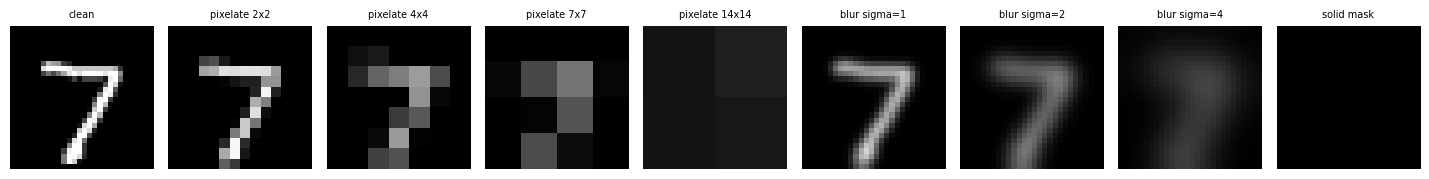

In [7]:
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(1.6 * len(CONDITIONS), 2))
for ax, (name, f) in zip(axes, CONDITIONS.items()):
    ax.imshow(f(Xte[:1])[0, 0].numpy(), cmap='gray', vmin=0, vmax=1)
    ax.set_title(name, fontsize=7)
    ax.axis('off')
plt.tight_layout()
plt.savefig('fig_examples.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Figure 2: test accuracy by condition (saved as fig_accuracy.png; greyscale, so it prints)

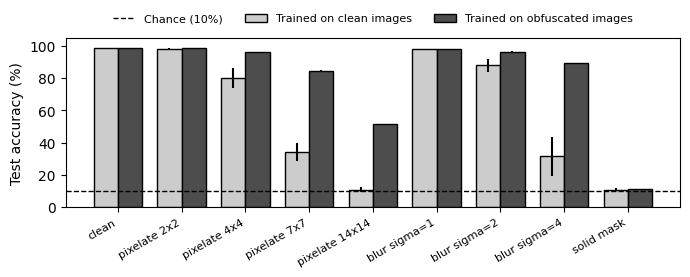

In [8]:
x = np.arange(len(df))
w = 0.38
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(x - w / 2, df['trained_on_clean_%'], w, yerr=df['trained_on_clean_sd'],
       color='0.8', edgecolor='black', label='Trained on clean images')
ax.bar(x + w / 2, df['trained_on_obfuscated_%'], w, yerr=df['trained_on_obfuscated_sd'],
       color='0.3', edgecolor='black', label='Trained on obfuscated images')
ax.axhline(10, color='black', linestyle='--', linewidth=1, label='Chance (10%)')
ax.set_xticks(x)
ax.set_xticklabels(df['condition'], rotation=30, ha='right', fontsize=8)
ax.set_ylabel('Test accuracy (%)')
ax.set_ylim(0, 105)
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, 1.2), ncol=3, frameon=False)
plt.tight_layout()
plt.savefig('fig_accuracy.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Optional: download the results and figures (Colab only)

In [9]:
try:
    from google.colab import files
    for name in ['results.csv', 'fig_examples.png', 'fig_accuracy.png']:
        files.download(name)
except ImportError:
    print("Not running on Colab: the files are in this notebook's folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>